Welcome to this tutorial, designed to help understand the basis of Graph Neural Networks. Let's begin by creating graphs and adjacency matrices. Then, we will import the dataset SOFI. And then we will test the frameworks CausalRCA and AlertRCA.

Import the packages.

In [60]:
import numpy as np
import pandas as pd
from pandas import ExcelWriter
from pandas import ExcelFile
import os
import glob
import re
import time, datetime
import requests
import pickle
import networkx as nx
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.autograd import Variable
from torch_geometric.data import Data
from torch_geometric.utils import from_networkx
from torch.optim.adam import Adam
from torch.autograd import Variable
from torch.utils.data.dataset import TensorDataset
from torch.utils.data import DataLoader
from torch.optim import lr_scheduler

import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from scipy.stats import pearsonr
import math

from abc import ABC
from typing import Dict
from typing import List
from typing import Set
from typing import Union

import scipy.linalg as slin

import json
from tqdm.notebook import tqdm, trange
import argparse

from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_recall_fscore_support

#from sknetwork.ranking import PageRank

parser = argparse.ArgumentParser()
parser.add_argument('--indx', type=int, default=0, help='index')
parser.add_argument('--atype', type=str, default='cpu-hog1_', help='anomaly type')
parser.add_argument('--gamma', type=float, default=0.25, help='gamma')
parser.add_argument('--eta', type=int, default=10, help='eta')
parser.add_argument('--epochs', type=int, default=None, help='Override number of epochs')
parser.add_argument('--data_file', type=str, default='', help='Chemin du fichier .pkl à analyser')
args, unknown = parser.parse_known_args()

Some experiments about graphs and adjacency matrix

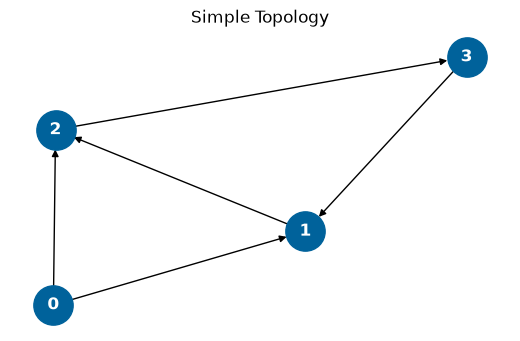

Adjacency matrix (A) :
 [[0. 1. 1. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]]

edge_index for the GNN (PyTorch Geometric) :
 tensor([[0, 0, 1, 2, 3],
        [1, 2, 2, 3, 1]])


In [61]:
# 1. Creation of a small directed graph
G = nx.DiGraph()
edges = [(0, 1), (1, 2), (2, 3), (3, 1), (0, 2)]  # Ex: Traffic flows between 5 nodes
G.add_edges_from(edges)

# 2. Vizualization
plt.figure(figsize=(5, 3))
nx.draw(G, with_labels=True, node_color='#00629B', font_color='white', 
        node_size=800, font_weight='bold', arrows=True)
plt.title("Simple Topology")
plt.show()

# 3. Adjacency matrix representation
adj_matrix = nx.to_numpy_array(G)
print("Adjacency matrix (A) :\n", adj_matrix)

# 4. Conversion
pyg_data = from_networkx(G)
print("\nedge_index for the GNN (PyTorch Geometric) :\n", pyg_data.edge_index)

Some tests with the SOFI dataset

In [62]:
DATA_PATH = r"C:\Users\audrey.nageotte\OneDrive - SPIE\Documents\ECRITURE ARTICLES\Tuto_GNN_CCNC\SOFI_CoreSwitch-I.csv"

sofi_df = pd.read_csv(DATA_PATH)
print(f"✅ Features of SOFI : {sofi_df.shape[0]} timestamps, {sofi_df.shape[1]} columns.")
display(sofi_df.head(3))

✅ Features of SOFI : 12971 timestamps, 35 columns.


,timestamp,range,ICMP_ping,ICMP_loss,ICMP_response_time,P_Inbound_packets_discarded,EX_Inbound_packets_discarded,P_Inbound_packets_with_errors,EX_Inbound_packets_with_errors,P_Bits_received,...,Device_uptime,SNMP_Availability,IN_Inbound_packets_discarded,IN_Inbound_packets_with_errors,IN_Bits_received,IN_Outbound_packets_discarded,IN_Outbound_packets_with_errors,IN_Bits_sent,IN_Operational_status,class
0,1556642700,119,1,0.0,0.0140,0,0,0,0,160,...,892,1,0,0,4664,0,0,44624,1,NE
1,1556642880,119,1,0.0,0.0170,0,0,0,0,152,...,1058,1,0,0,9776,0,0,101480,1,NE
2,1556643060,119,1,0.0,0.0115,0,0,0,1,152,...,1224,1,0,0,9168,0,0,152728,1,NE


In [63]:
file_path = Path("C:/Users/audrey.nageotte/OneDrive - SPIE/Documents/ECRITURE ARTICLES/Tuto_GNN_CCNC")
file_path.parent.mkdir(parents=True, exist_ok=True) 

file1_num = sofi_df.drop(
    columns=[
        "range", "IN_Interface_type", "EX_Interface_type", "P_Interface_type",
        "SNMP_availability", "P_Bits_sent", "EX_Bits_sent", "IN_Bits_sent",
        "IN_Bits_received", "EX_Speed", "IN_Speed", "P_Operational_status",
        "EX_Operational_status", "IN_Operational_status", "class"
    ],
    errors="ignore"
)

#Savings
output_file = file_path / "SOFI_CoreSwitch-I_processed.csv"
file1_num.to_csv(output_file, index=False, sep=",", encoding="utf-8")
print(f"✅ Saved file : {file_path.name}")

✅ Saved file : Tuto_GNN_CCNC


In [64]:
input_file = Path("C:/Users/audrey.nageotte/OneDrive - SPIE/Documents/ECRITURE ARTICLES/Tuto_GNN_CCNC/SOFI_CoreSwitch-I_processed.csv")
file = pd.read_csv(input_file, delimiter=",")

print("\n--- Calcul of the adjacency matrix using Pearson correlations ---")

# 1. Forcer la conversion en valeurs numériques (remplace 'NE' par NaN)
file_numeric = file.apply(pd.to_numeric, errors='coerce')

# 2. Calculer la corrélation sur les valeurs propres
pearson_df = file_numeric.corr(method='pearson').fillna(0)

# 3. Filtrage (Sparsification)
threshold = 0.7
adj_matrix_numpy = pearson_df.to_numpy(copy=True) 
adj_matrix_numpy[np.abs(adj_matrix_numpy) < threshold] = 0
np.fill_diagonal(adj_matrix_numpy, 0)

pearson_sparse_df = pd.DataFrame(adj_matrix_numpy, index=pearson_df.columns, columns=pearson_df.columns)

print("\n✅ Adjacency matrix (sparse) :\n", pearson_sparse_df.head())


--- Calcul of the adjacency matrix using Pearson correlations ---

✅ Adjacency matrix (sparse) :
                              timestamp  ICMP_ping  ICMP_loss  \
timestamp                          0.0   0.000000        0.0   
ICMP_ping                          0.0   0.000000        0.0   
ICMP_loss                          0.0   0.000000        0.0   
ICMP_response_time                 0.0   0.914703        0.0   
P_Inbound_packets_discarded        0.0   0.894187        0.0   

                             ICMP_response_time  P_Inbound_packets_discarded  \
timestamp                              0.000000                     0.000000   
ICMP_ping                              0.914703                     0.894187   
ICMP_loss                              0.000000                     0.000000   
ICMP_response_time                     0.000000                     0.817739   
P_Inbound_packets_discarded            0.817739                     0.000000   

                             EX_Inb

In [ ]:
#je pense que c'est OK de designer qu'une seule matrice d'adjacence (pas besoin de faire Kendall, Spearman...)

CausalRCA

In [65]:
import json
import math
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [66]:
# =====================================================================
# SECTION 1: NEURAL MODULES (DAG-GNN ARCHITECTURE)
# =====================================================================

def preprocess_adj_new(adj: torch.Tensor) -> torch.Tensor:
    """Computes (I - A^T) for causal message passing in the Encoder."""
    return torch.eye(adj.size(0), dtype=torch.float64) - adj.transpose(0, 1)

def preprocess_adj_new1(adj: torch.Tensor) -> torch.Tensor:
    """Computes (I - A^T)^(-1) for data reconstruction in the Decoder."""
    return torch.inverse(torch.eye(adj.size(0), dtype=torch.float64) - adj.transpose(0, 1))

class MLPEncoder(nn.Module):
    def __init__(
        self,
        num_nodes: int,
        x_dims: int,
        h_dim: int,
        z_dim: int,
        adj_init: np.ndarray,
        dropout: float = 0.0,):
        super(MLPEncoder, self).__init__()
        self.adj_A = nn.Parameter(torch.tensor(adj_init, dtype=torch.float64), requires_grad=True)
        self.Wa = nn.Parameter(torch.zeros(z_dim, dtype=torch.float64))
        self.fc1 = nn.Linear(x_dims, h_dim).double()
        self.fc2 = nn.Linear(h_dim, z_dim).double()
        self.dropout = nn.Dropout(dropout)
        self.init_weights()

    def init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight.data)
                m.bias.data.fill_(0.0)

    def forward(self, x: torch.Tensor):
        adj_A1 = torch.sinh(3.0 * self.adj_A)
        adj_Aforz = preprocess_adj_new(adj_A1)
        h = F.relu(self.fc1(x))
        h = self.dropout(h)
        h = self.fc2(h)
        logits = torch.matmul(adj_Aforz, h + self.Wa) - self.Wa
        return logits, adj_A1

class MLPDecoder(nn.Module):
    def __init__(
        self,
        num_nodes: int,
        z_dim: int,
        x_dims: int,
        h_dim: int,
        dropout: float = 0.0,):
        super(MLPDecoder, self).__init__()
        self.fc1 = nn.Linear(z_dim, h_dim).double()
        self.fc2 = nn.Linear(h_dim, x_dims).double()
        self.dropout = nn.Dropout(dropout)
        self.init_weights()

    def init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight.data)
                m.bias.data.fill_(0.0)

    def forward(self, z: torch.Tensor, origin_A: torch.Tensor, Wa: torch.Tensor):
        adj_A_inv = preprocess_adj_new1(origin_A)
        mat_z = torch.matmul(adj_A_inv, z + Wa) - Wa
        h = F.relu(self.fc1(mat_z))
        h = self.dropout(h)
        x_rec = self.fc2(h)
        return x_rec

In [67]:
# =====================================================================
# SECTION 2: LOSS FUNCTIONS & ACYCLICITY PENALTY h(A)
# =====================================================================
def matrix_poly(matrix: torch.Tensor, d: int) -> torch.Tensor:
    """Computes (I + A^2 / d)^d to approximate tr(exp(A^2))."""
    x = torch.eye(d, dtype=torch.float64) + torch.div(matrix, d)
    return torch.matrix_power(x, d)

def compute_h_A(A: torch.Tensor, d: int) -> torch.Tensor:
    """Acyclicity constraint penalty h(A) = tr(exp(A o A)) - d.
    h(A) = 0 if and only if graph A is a Directed Acyclic Graph (DAG).
    """
    expm_A = matrix_poly(A * A, d)
    return torch.trace(expm_A) - d

def nll_gaussian(preds: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    """Negative Log-Likelihood assuming Gaussian noise distribution."""
    return F.mse_loss(preds, target, reduction="sum") / target.size(0)

def kl_gaussian_sem(preds: torch.Tensor) -> torch.Tensor:
    """Kullback-Leibler divergence for latent representation regularization."""
    return 0.5 * (preds**2).sum() / preds.size(0)

In [68]:
# =====================================================================
# SECTION 3: SOFI DATASET LOADING & TRAINING LOOP (FIXED READ_CSV)
# =====================================================================
# Set random seeds for reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
# Hyperparameters
epochs = 200
k_max_iter = 20
lr = 1e-3
graph_threshold = 0.3
tau_A = 0.001
c_A = 1.0
lambda_A = 0.0
eta = 10.0
gamma = 0.25
h_tol = 1e-8

input_path = Path("C:/Users/audrey.nageotte/OneDrive - SPIE/Documents/ECRITURE ARTICLES/Tuto_GNN_CCNC/SOFI_CoreSwitch-I_processed.csv")

if not input_path.exists():
    raise FileNotFoundError(f"SOFI dataset not found at: {input_path}")

df_sofi = pd.read_csv(
    input_path,
    sep=None,             # Auto-detect separator (comma, semicolon, or tab)
    engine="python",      # Robust parser engine
    on_bad_lines="skip"   # Skip malformed rows if any exist
)

df_sofi = df_sofi.loc[:, ~df_sofi.columns.str.contains('^Unnamed')]

# Remove timestamp / time columns if present
for time_col in ["timestamp", "Time", "time", "date"]:
    if time_col in df_sofi.columns:
        df_sofi = df_sofi.drop(columns=[time_col])

# Fill any NaN values that might prevent float conversion
df_sofi = df_sofi.fillna(0.0)
# Convert non-numeric values (like 'NE' or text) to NaN, then fill with 0.0
df_numeric = df_sofi.apply(pd.to_numeric, errors='coerce').fillna(0.0)
# Update node names and dimensions based on cleaned numeric data
names = list(df_numeric.columns)
num_nodes = len(names)
num_samples = len(df_sofi)
print(f">>> SOFI Dataset successfully loaded!")
print(f"    Total Samples (N): {num_samples}")
print(f"    Detected Metrics / Nodes (D): {num_nodes}")
print(f"    Metrics List: {names[:5]} ... (total {num_nodes})")
# Z-Score Normalization on clean numeric array
raw_data = df_numeric.values.astype(np.float64)
mean_vals = np.mean(raw_data, axis=0)
std_vals = np.std(raw_data, axis=0)
std_vals[std_vals == 0] = 1.0  # Prevent division by zero
normalized_data = (raw_data - mean_vals) / std_vals
# Format into 3D Tensor [N, D, K] with K=1 feature per metric
X_data = np.expand_dims(normalized_data, axis=2)  # Shape: (N, D, 1)
# Initialize DAG-GNN Model
adj_init = np.zeros((num_nodes, num_nodes))
encoder = MLPEncoder(num_nodes=num_nodes,
    x_dims=1,
    h_dim=64,
    z_dim=1,
    adj_init=adj_init,
    dropout=0.0,)
decoder = MLPDecoder(num_nodes=num_nodes, z_dim=1, x_dims=1, h_dim=64, dropout=0.0)
optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=lr)

# Augmented Lagrangian Optimization Loop
print(f"\n>>> Starting DAG-GNN Causal Discovery Training on SOFI Dataset...")
h_A_old = np.inf
start_time = time.time()
for step_k in range(k_max_iter):
    print(f"\n--- Outer Iteration {step_k+1}/{k_max_iter} | c_A = {c_A:.1e} | lambda_A = {lambda_A:.4f} ---")
    for epoch in range(epochs):
        encoder.train()
        decoder.train()
        inputs = torch.tensor(X_data, dtype=torch.float64)
        optimizer.zero_grad()
        z_latent, origin_A = encoder(inputs)
        x_rec = decoder(z_latent, origin_A, encoder.Wa)
        # Calculate losses
        loss_nll = nll_gaussian(x_rec, inputs)
        loss_kl = kl_gaussian_sem(z_latent)
        h_A = compute_h_A(origin_A, num_nodes)
        sparse_loss = tau_A * torch.sum(torch.abs(origin_A))
        # Lagrangian Objective Function
        loss = (loss_nll
            + loss_kl
            + lambda_A * h_A
            + 0.5 * c_A * (h_A**2)
            + 100.0 * torch.trace(origin_A * origin_A)
            + sparse_loss)
        loss.backward()
        optimizer.step()
    # Update Lagrangian constraint parameters
    with torch.no_grad():
        h_A_current = compute_h_A(origin_A, num_nodes).item()
    print(f"    End of sub-problem: h(A) = {h_A_current:.6f}")
    if h_A_current > gamma * h_A_old:
        c_A *= eta
    else:
        lambda_A += c_A * h_A_current
        h_A_old = h_A_current
    if h_A_current <= h_tol or c_A >= 1e10:
        print("    Acyclicity constraint satisfied: Valid DAG discovered.")
        break
print(f"\n>>> Training completed in {time.time() - start_time:.2f} seconds.")

>>> SOFI Dataset successfully loaded!
    Total Samples (N): 12971
    Detected Metrics / Nodes (D): 20
    Metrics List: ['ICMP_ping', 'ICMP_loss', 'ICMP_response_time', 'P_Inbound_packets_discarded', 'EX_Inbound_packets_discarded'] ... (total 20)

>>> Starting DAG-GNN Causal Discovery Training on SOFI Dataset...

--- Outer Iteration 1/20 | c_A = 1.0e+00 | lambda_A = 0.0000 ---
    End of sub-problem: h(A) = 0.109982

--- Outer Iteration 2/20 | c_A = 1.0e+00 | lambda_A = 0.1100 ---
    End of sub-problem: h(A) = 0.039915

--- Outer Iteration 3/20 | c_A = 1.0e+01 | lambda_A = 0.1100 ---
    End of sub-problem: h(A) = 0.012377

--- Outer Iteration 4/20 | c_A = 1.0e+01 | lambda_A = 0.2338 ---
    End of sub-problem: h(A) = 0.006479

--- Outer Iteration 5/20 | c_A = 1.0e+02 | lambda_A = 0.2338 ---
    End of sub-problem: h(A) = 0.003584

--- Outer Iteration 6/20 | c_A = 1.0e+03 | lambda_A = 0.2338 ---
    End of sub-problem: h(A) = 0.001791

--- Outer Iteration 7/20 | c_A = 1.0e+03 | lamb

In [70]:
# =====================================================================
# SECTION 4: ROOT CAUSE ANALYSIS (PAGERANK & CAUSAL GRAPH)
# =====================================================================
adj_matrix = origin_A.data.clone().cpu().numpy()
adj_matrix[np.abs(adj_matrix) < graph_threshold] = 0.0

# 1. Save and Plot Discovered Causal Graph
G_causal = nx.from_numpy_array(adj_matrix, create_using=nx.DiGraph)
mapping = {i: names[i] for i in range(num_nodes)}
G_causal = nx.relabel_nodes(G_causal, mapping)
plt.figure(figsize=(10, 8))
pos = nx.circular_layout(G_causal)
nx.draw(
    G_causal,
    pos=pos,
    with_labels=True,
    node_color="skyblue",
    node_size=2000,
    arrowstyle="->",
    arrowsize=20,
    font_weight="bold",
    font_size=8,
)
plt.title("Discovered Causal Graph on SOFI Dataset (DAG-GNN)")
plt.tight_layout()
plt.savefig("sofi_causalrca_graph.png")
plt.close()
print("Saved Causal Graph visual to: 'sofi_causalrca_graph.png'")

# 2. PageRank Root Cause Ranking (Transposed Graph A^T)
# Inverting edge direction routes flow toward the root cause nodes
G_pagerank = nx.from_numpy_array(np.abs(adj_matrix.T), create_using=nx.DiGraph)
scores = nx.pagerank(G_pagerank, alpha=0.85, max_iter=1000)

ranking = [{"Rank": r + 1, "Metric_Name": names[idx], "Root_Cause_Score": scores[idx]}
    for r, idx in enumerate(sorted(scores, key=scores.get, reverse=True))]

df_ranking = pd.DataFrame(ranking)
print("\n=======================================================")
print("          ROOT CAUSE ANALYSIS RANKING (SOFI)           ")
print("=======================================================")
print(df_ranking.to_string(index=False))

# Export JSON summary
output_json_path = "causalrca_sofi_results.json"
with open(output_json_path, "w") as f:
    json.dump({"dataset_file": str(input_path),
            "num_nodes": num_nodes,
            "nodes": names,
            "adjacency_matrix": adj_matrix.tolist(),
            "root_cause_ranking": ranking,},f,
        indent=4,)
print(f"\nSaved RCA summary to: '{output_json_path}'")

C:\Users\audrey.nageotte\AppData\Local\Temp\ipykernel_32680\759246364.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved Causal Graph visual to: 'sofi_causalrca_graph.png'

          ROOT CAUSE ANALYSIS RANKING (SOFI)           
 Rank                     Metric_Name  Root_Cause_Score
    1              ICMP_response_time          0.088729
    2                       ICMP_ping          0.047962
    3                       ICMP_loss          0.047962
    4     P_Inbound_packets_discarded          0.047962
    5    EX_Inbound_packets_discarded          0.047962
    6   P_Inbound_packets_with_errors          0.047962
    7  EX_Inbound_packets_with_errors          0.047962
    8                 P_Bits_received          0.047962
    9                EX_Bits_received          0.047962
   10    P_Outbound_packets_discarded          0.047962
   11   EX_Outbound_packets_discarded          0.047962
   12  P_Outbound_packets_with_errors          0.047962
   13 EX_Outbound_packets_with_errors          0.047962
   14                         P_Speed          0.047962
   15                   Device_uptime         

AlertRCA

In [71]:
# =====================================================================
# SECTION 1: IMPORTS & SETUP
# =====================================================================
import argparse
import copy
import json
import logging
import os
import random
import time
from datetime import datetime
from math import floor
from pathlib import Path
from typing import Any, Callable, Dict, List, Tuple, Type, Union

import networkx as nx
import numpy as np
import pandas as pd
import pytz
import torch
import torch.nn as nn
import torch.nn.functional as F
from einops import rearrange
from torch_geometric.nn import SAGEConv

logger = logging.getLogger('alert_rca')
logger.setLevel(logging.INFO)

# Global settings for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [72]:
# =====================================================================
# SECTION 2: NEURAL MODULES (GRU ENCODER & DAG-ATTENTION)
# =====================================================================

class GRUFeatureModule(nn.Module):
    """Encodes time series metrics into a latent vector using GRU."""
    def __init__(self, input_size: torch.Size, embedding_size: int, num_layers: int = 1):
        super().__init__()
        self.x_dim = input_size[0] # Number of metrics (e.g., 1)
        self.n_ts = input_size[1]  # Window size (e.g., 10)
        self.z_dim = embedding_size
        
        self.encoder = nn.GRU(
            input_size=self.x_dim, hidden_size=self.z_dim, num_layers=num_layers
        )
        
        # Flattens and projects GRU output to final embedding
        self.unify_mapper = nn.Sequential(
            nn.Conv1d(in_channels=self.z_dim, out_channels=10, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Flatten(start_dim=-2),
            nn.Linear(10 * self.n_ts, embedding_size)
        )

    def forward(self, input_x: torch.Tensor):
        # input_x shape: (metrics, time_steps)
        _, n_ts = input_x.size()
        x = rearrange(input_x, "m t -> t 1 m", m=self.x_dim, t=n_ts)
        z, _ = self.encoder(x)
        z = rearrange(z, "t 1 z -> z t", z=self.z_dim, t=n_ts)
        # Add batch dimension for Conv1d
        z = z.unsqueeze(0) 
        embedding = self.unify_mapper(z).squeeze(0)
        return embedding

class RuleDict(nn.Module):
    """DAG-Attention (DAGAT) mechanism to compute transition probabilities."""
    def __init__(self, hid_channels=8, attention_channels=3, heads=4):
        super().__init__()
        self.heads = heads
        self.hid_channels = hid_channels
        self.attention_channels = attention_channels
        self.scale = np.sqrt(attention_channels)
        self.deep_transformer = nn.Linear(hid_channels, hid_channels, bias=False)
        self.start_embedding = nn.Linear(hid_channels * 2, hid_channels, bias=False)
        self.root_cause_fc = nn.Sequential(
            nn.Linear(hid_channels * 2, 64),
            nn.GELU(),
            nn.Linear(64, 1, bias=False )
        )
        # Q, K, V projections for DAGAT
        self.alpha_w_q = nn.Linear(hid_channels, attention_channels * heads, bias=False)
        self.alpha_w_k = nn.Linear(hid_channels, attention_channels * heads, bias=False)

    def forward(self, event0, event1, direction='d'):
        # Compute Q and K
        Q = self.alpha_w_q(event0.unsqueeze(0)).view(1, self.heads, self.attention_channels)
        K = self.alpha_w_k(event1.unsqueeze(0)).view(1, self.heads, self.attention_channels)
        
        # Scaled Dot-Product Attention
        attention = (Q * K).sum(dim=-1) / self.scale
        return torch.clamp(torch.exp(attention.sum()) - 0.5, min=0.0)

class GNN(nn.Module):
    """GraphSAGE down/up propagation through the network topology."""
    def __init__(self, in_channels, hidden_channels):
        super().__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)

    def forward(self, x, edge_index):
        x = F.leaky_relu(self.conv1(x, edge_index), 0.2)
        x = self.conv2(x, edge_index)
        return x

In [73]:
# =====================================================================
# SECTION 3: DEEP_RCA_RANK (RANDOM WALK INFERENCE - FIXED DEEPCOPY)
# =====================================================================

def deep_rca_rank(G: nx.DiGraph, deep_rule, max_iter=5):
    """Performs localized random walk to rank root causes."""
    if len(G) == 0:
        return {}
    D = G.to_directed() if not G.is_directed() else G

    # 1. Extract feature vectors using GRU mapping
    for i, n in enumerate(D):
        detail = D.nodes[n]['details']
        D.nodes[n]['meta_vector'] = deep_rule.metric_projector[detail['type']](detail['metric'])
    x = torch.stack([D.nodes[n]['meta_vector'] for n in D], dim=0)
    # Use to_scipy_sparse_array for NetworkX 3.0+ compatibility
    eg_scipy = nx.to_scipy_sparse_array(D, format='coo')
    eg_index = torch.tensor(np.vstack((eg_scipy.row, eg_scipy.col)), dtype=torch.long)
    
    # 2. GraphSAGE propagation
    res = deep_rule.gnn['down'](x, eg_index)
    for i, n in enumerate(D):
        D.nodes[n]['hidden_vector'] = res[i]
    
    # 3. Compute edge transition weights using DAGAT
    end_weights = {}
    for u, v, d in D.edges(data='direction'):
        pu, pv = D.nodes[u]['hidden_vector'], D.nodes[v]['hidden_vector']
        D[u][v]['weight'] = deep_rule.rule_dict(pu, pv, d)
        
    for n in D:
        end_weights[n] = deep_rule.rule_dict(D.nodes[n]['hidden_vector'], D.nodes[n]['hidden_vector'])

    # Softmax normalization over outgoing edges
    for n in D:
        w_list = [D[n][nbr]['weight'] for nbr in D[n]] + [end_weights[n]]
        w_list = F.softmax(torch.stack(w_list), dim=0)
        for i, nbr in enumerate(D[n]):
            D[n][nbr]['weight'] = w_list[i]
        end_weights[n] = w_list[-1]

    # 4. Random Walk Simulation (forward_cwx)
    x_state = {n: D.nodes[n]['meta_vector'] for n in D}
    
    for _ in range(max_iter):
        # FIX: Shallow copy dictionary reference instead of copy.deepcopy on autograd tensors
        x_last = x_state.copy()
        x_state = dict.fromkeys(D, None)
        
        for n in D:
            for nbr in D[n]:
                delta = x_last[n] * D[n][nbr]['weight']
                x_state[nbr] = delta if x_state[nbr] is None else x_state[nbr] + delta
                
        for n in D:
            if x_state[n] is not None:
                x_state[n] = F.elu(deep_rule.rule_dict.deep_transformer(x_state[n]))
            if x_state[n] is None:
                x_state[n] = D.nodes[n]['meta_vector'].clone()
            else:
                x_state[n] = x_state[n] + D.nodes[n]['meta_vector']

    # 5. Predict final root cause scores
    res_scores = {}
    for n in D:
        combined = torch.cat([D.nodes[n]['meta_vector'], x_state[n]], dim=-1)
        res_scores[n] = deep_rule.rule_dict.root_cause_fc(combined * end_weights[n])
        
    # Softmax output ranking
    nodes = list(res_scores.keys())
    scores = F.softmax(torch.stack(list(res_scores.values())), dim=0)
    return {nodes[i]: scores[i] for i in range(len(nodes))}

In [74]:
# =====================================================================
# SECTION 4: DEEPRULE WRAPPER & SOFI DATASET ADAPTER (FIXED NUMERIC)
# =====================================================================

class DeepRule(nn.Module):
    """Main wrapper combining GRU, GNN, and DAGAT."""
    def __init__(self, rca_parameters, node_types):
        super().__init__()
        self.metric_projector = nn.ModuleDict({
            nt: GRUFeatureModule(rca_parameters['gru_size'][nt], rca_parameters['hid_channels']) 
            for nt in node_types
        })
        self.rule_dict = RuleDict(rca_parameters['hid_channels'], rca_parameters['attention_channels'])
        self.gnn = nn.ModuleDict({
            'down': GNN(rca_parameters['hid_channels'], rca_parameters['hid_channels'])
        })

class SOFIDataset(torch.utils.data.Dataset):
    """Clean Adapter for SOFI CSV to AlertRCA Format."""
    def __init__(self, csv_path, window_size=10):
        df = pd.read_csv(csv_path)
        
        # 1. Drop timestamp/time columns if present
        df_metrics = df.drop(columns=['timestamp', 'Time', 'time', 'date'], errors='ignore')
        
        # 2. Coerce string values (e.g. 'NE') to NaN, fill with 0.0
        df_numeric = df_metrics.apply(pd.to_numeric, errors='coerce').fillna(0.0)
        
        # 3. Store metric names and cast array explicitly to float32
        self.node_names = list(df_numeric.columns)
        self.features = df_numeric.values.astype(np.float32)
        self.window_size = window_size
        
        # Build base topology graph (linear chain for demo)
        self.graph = nx.DiGraph()
        for name in self.node_names:
            self.graph.add_node(name, type='Service')
        for i in range(len(self.node_names) - 1):
            self.graph.add_edge(self.node_names[i], self.node_names[i+1], direction='d')

    def __len__(self):
        return len(self.features) - self.window_size

    def __getitem__(self, idx):
        # Slice window (shape: window_size, num_nodes)
        window = self.features[idx : idx + self.window_size]
        g_instance = copy.deepcopy(self.graph)
        
        # Attach metrics to graph nodes
        for i, node in enumerate(self.node_names):
            g_instance.nodes[node]['details'] = {
                'type': 'Service',
                # Shape: (metrics=1, time_steps=window_size)
                'metric': torch.tensor(window[:, i]).unsqueeze(0).float()
            }
            
        fake_label = [self.node_names[0]] 
        return fake_label, idx, g_instance

In [ ]:
# =====================================================================
# SECTION 5: TRAINING & INFERENCE EXECUTION
# =====================================================================

# 1. Load SOFI Data
input_path = "C:/Users/audrey.nageotte/OneDrive - SPIE/Documents/ECRITURE ARTICLES/Tuto_GNN_CCNC/SOFI_CoreSwitch-I_processed.csv"
dataset = SOFIDataset(input_path, window_size=10)

# 2. Configure AlertRCA Architecture parameters
rca_parameters = {
    'hid_channels': 8,
    'attention_channels': 3,
    'heads': 4,
    'gru_size': {'Service': torch.Size([1, 10])} # 1 metric feature, 10 time steps
}

# 3. Instantiate Model & Optimizer
model = DeepRule(rca_parameters, node_types=['Service'])
optimizer = torch.optim.Adam(model.parameters(), lr=4e-3)
num_epochs = 5 #mettre 20 epochs plutôt que 5
train_sample_count = min(50, len(dataset))

print(">>> Starting AlertRCA Training on SOFI Dataset...")
model.train()

for epoch in range(num_epochs):
    epoch_loss = 0.0
    processed_samples = 0
    
    for i in range(train_sample_count): 
        labels, ts, G = dataset[i]
        
        optimizer.zero_grad()
        
        # Forward pass through DAGAT & Random Walk
        res = deep_rca_rank(G, model)
        
        if res:
            target_node = labels[0]
            if target_node in res:
                # Loss: Negative Log-Likelihood of the true root cause
                loss = -torch.log(res[target_node] + 1e-8)
                loss.backward()
                
                # Gradient clipping for GRU & DAGAT stability
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                
                epoch_loss += loss.item()
                processed_samples += 1
                
    avg_loss = epoch_loss / max(processed_samples, 1)
    print(f"Epoch [{epoch+1}/{num_epochs}] | Average NLL Loss: {avg_loss:.4f}")

# 4. Evaluation / Inference Phase
print("\n>>> Testing AlertRCA Root Cause Inference...")
model.eval()

# Safeguard index in case dataset length is less than 100
test_idx = min(100, len(dataset) - 1)
labels, ts, G_test = dataset[test_idx]

with torch.no_grad():
    res_scores = deep_rca_rank(G_test, model)

# Sort predictions by confidence score (descending)
sorted_rca = sorted(res_scores.items(), key=lambda item: item[1].item(), reverse=True)

print("\n==========================================")
print("     ALERTRCA ROOT CAUSE RANKING (SOFI)   ")
print("==========================================")
for rank, (node, score) in enumerate(sorted_rca):
    print(f" #{rank+1} : {node:<25} (Confidence: {score.item():.4f})")

>>> Starting AlertRCA Training on SOFI Dataset...
Epoch [1/5] | Average NLL Loss: 1.1705
Epoch [2/5] | Average NLL Loss: 0.0000
Epoch [3/5] | Average NLL Loss: 0.0000
Epoch [4/5] | Average NLL Loss: 0.0000
Epoch [5/5] | Average NLL Loss: 0.0000

>>> Testing AlertRCA Root Cause Inference...

     ALERTRCA ROOT CAUSE RANKING (SOFI)   
 #1 : ICMP_ping                 (Confidence: 1.0000)
 #2 : EX_Bits_received          (Confidence: 0.0000)
 #3 : Device_uptime             (Confidence: 0.0000)
 #4 : P_Bits_received           (Confidence: 0.0000)
 #5 : P_Speed                   (Confidence: 0.0000)
 #6 : P_Outbound_packets_discarded (Confidence: 0.0000)
 #7 : SNMP_Availability         (Confidence: 0.0000)
 #8 : EX_Outbound_packets_discarded (Confidence: 0.0000)
 #9 : IN_Inbound_packets_discarded (Confidence: 0.0000)
 #10 : EX_Inbound_packets_with_errors (Confidence: 0.0000)
 #11 : P_Outbound_packets_with_errors (Confidence: 0.0000)
 #12 : EX_Outbound_packets_with_errors (Confidence: 0.0000)
